# Embedding và dữ liệu chuỗi

Các câu có độ dài khác nhau, trong khi tensor cần mọi dòng dài bằng nhau. Cách thường dùng là thêm token PAD vào cuối câu ngắn cho đủ độ dài, rồi dùng mask để model bỏ qua các vị trí PAD. Bài này học embedding (biến mỗi từ thành một vector), padding, mask, pooling (gộp các vector của câu thành một vector) và RNN, mạng đọc chuỗi lần lượt từng từ. Điều cần kiểm nhất: thêm PAD không được làm đổi kết quả của câu.

> **Mục tiêu**
>
> - Dùng embedding để biến token thành vector.
> - Dùng padding và mask cho các câu dài ngắn khác nhau.
> - Tính mean pooling bỏ qua PAD; lấy đúng trạng thái RNN khi có PAD.
> - Biết vì sao RNN khó học chuỗi dài và LSTM sửa thế nào.

## ID là địa chỉ, không phải độ lớn

Giả sử mã “đồ_thị” là 2 và “dp” là 3. Không có nghĩa dp lớn hơn đồ thị một đơn vị về kiến thức. Đưa ID thẳng vào lớp linear như một số thực sẽ tạo một quan hệ số không có cơ sở. Embedding dùng ID làm địa chỉ hàng trong bảng $E$ shape `(V,d)`, với $V$ là số token trong vocabulary, $d$ là số thành phần vector.

One-hot $\mathbf u_k$ (số 1 ở vị trí $k$, còn lại 0) nhân bảng cũng chọn đúng hàng $k$: $\mathbf u_k^\top E=E_k$. Lookup trực tiếp cho cùng kết quả mà không phải tạo one-hot rộng $V$ cột.

Các hàng của embedding là tham số; gradient từ loss sửa các hàng đã được dùng. Khi khởi tạo ngẫu nhiên, vector chưa có nghĩa ngôn ngữ. Ý nghĩa đến từ mục tiêu học trên dữ liệu (mục backprop dưới đây) hoặc từ một bảng pretrained đã học sẵn.

Ta quy ước `PAD=0`, `UNK=1`, đồ_thị=2, dp=3, toán=4. UNK là token thật để biểu diễn token chưa biết; PAD là phần điền cho bảng. Hai vai trò cần hai ID khác nhau. Vocabulary và mapping phải lưu cùng checkpoint: fit vocabulary trên train, token mới gặp ở test ánh xạ về UNK (hoặc do tokenizer đã có xử lý).

Bảng có $V \cdot d$ tham số: `nn.Embedding(30000, 768)` có 23 040 000. Vocabulary lớn hơn thì chuỗi ngắn đi nhưng bảng embedding và lớp ra cũng to theo. Thêm token mới vào tokenizer thì bảng phải thêm hàng tương ứng, với Hugging Face là `model.resize_token_embeddings(len(tokenizer))`; quên bước này thì ID mới vượt khỏi bảng.

**Hỏi nhanh.** Một bạn đưa thẳng cột ID, với đồ_thị = 2, dp = 3, toán = 4, vào `nn.Linear(1, 8)` như một feature số. Câu nào đúng?

- A. Linear tự học một vector riêng cho từng ID, giống Embedding
- B. Đầu ra là hàm tuyến tính của ID, nên đánh số lại là đổi model
- C. Chuẩn hóa ID bằng mean và std trước thì thành lookup đúng nghĩa
- D. Không sao, nếu ID được gán theo thứ tự tần suất xuất hiện

<details><summary>Đáp án</summary>

B. Đầu ra là hàm tuyến tính của ID, nên đánh số lại là đổi model

Với một feature, đầu ra là $w\cdot\text{ID} + b$. Ba token nằm trên một đường thẳng, nên hiệu đầu ra giữa `toán` và `dp` buộc phải bằng hiệu giữa `dp` và `đồ_thị`. Linear không có chỗ để mỗi ID có một vector tự do. Chuẩn hóa chỉ dời và co ID lại, quan hệ vẫn tuyến tính. Xếp theo tần suất chỉ là một cách đánh số khác, cũng không làm ID thành một độ lớn có nghĩa. Embedding thì cho mỗi ID một hàng riêng.

</details>

**Hỏi nhanh.** Vocabulary có 50 000 token, embedding rộng 300, batch token ID có shape `(32, 128)`. Nếu tạo one-hot float32 rồi nhân với bảng thay cho lookup, riêng tensor one-hot chiếm khoảng bao nhiêu?

- A. Khoảng 4.9 MB, bằng đầu ra lookup `(32, 128, 300)`
- B. Khoảng 60 MB, bằng bảng embedding `(50000, 300)`
- C. Khoảng 819 MB, so với 4.9 MB của đầu ra lookup
- D. Khoảng 16 KB, vì one-hot chỉ lưu một số 1 cho mỗi token

<details><summary>Đáp án</summary>

C. Khoảng 819 MB, so với 4.9 MB của đầu ra lookup

One-hot dày lưu cả các số 0: $32\cdot 128\cdot 50\,000\cdot 4 \approx 8.2\cdot 10^8$ byte. Lookup trả thẳng ra `(32, 128, 300)`, tức $32\cdot 128\cdot 300\cdot 4 \approx 4.9\cdot 10^6$ byte. Bảng 60 MB thì cách nào cũng cần. 16 KB là cách lưu thưa, chỉ ghi vị trí số 1, không phải tensor one-hot dày mà phép nhân cần.

</details>

## Padding tạo bảng, mask giữ ý nghĩa

Trong CP, thường lưu độ dài bên cạnh mảng chứa dư. Mask cũng là thông tin ấy nhưng biểu diễn theo từng ô. `pad_sequence` tạo độ dài bằng chuỗi dài nhất trong batch, không nhất thiết độ dài toàn dataset. Nếu giới hạn độ dài bằng truncation, ta đang bỏ thông tin thật và phải chọn giới hạn theo bài toán.

In [ ]:
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence

torch.set_num_threads(1)
torch.manual_seed(37)
PAD, UNK = 0, 1
sequences = [torch.tensor([2, 3]), torch.tensor([3]), torch.tensor([4, 2, 3])]
ids = pad_sequence(sequences, batch_first=True, padding_value=PAD)
valid_mask = ids.ne(PAD)
print(ids.tolist())
print(valid_mask.int().tolist())
print('lengths:', valid_mask.sum(dim=1).tolist())

[[2, 3, 0], [3, 0, 0], [4, 2, 3]]
[[1, 1, 0], [1, 0, 0], [1, 1, 1]]
lengths: [2, 1, 3]


Đọc độ dài $2,1,3$; chiều bảng là `(3,3)` vì có ba mẫu và chuỗi dài nhất có ba token. Tokenizer chi tiết ở chương 6; bài này bắt đầu khi đã có token ID. Index embedding phải là số nguyên trong `[0,V)`, không được chuẩn hóa ID bằng mean/std như feature liên tục.

Với tokenizer của Hugging Face, `padding=True` đệm tới chuỗi dài nhất của batch, còn `truncation=True, max_length=8` cắt trước những chuỗi dài hơn 8: hai câu 5 và 11 token đều thành 8.



**Hỏi nhanh.** Một batch gồm ba câu dài 5, 12 và 7 token. Câu dài nhất của cả dataset có 200 token. `pad_sequence(..., batch_first=True)` cho ra tensor shape gì, và có bao nhiêu ô PAD?

- A. `(3, 12)`, 12 ô PAD
- B. `(12, 3)`, 12 ô PAD
- C. `(3, 12)`, không lưu ô PAD nào
- D. `(3, 200)`, 576 ô PAD

<details><summary>Đáp án</summary>

A. `(3, 12)`, 12 ô PAD

Chuỗi dài nhất trong batch có 12 token, nên bảng có $3\cdot 12 = 36$ ô. Trong đó có $5 + 12 + 7 = 24$ token thật, còn lại 12 ô PAD. Độ dài của cả dataset chỉ xuất hiện khi tự pad tới một `max_len` cố định. `(12, 3)` là cách xếp khi `batch_first=False`. Mask không xóa ô PAD khỏi tensor, chỉ đánh dấu chúng.

</details>

## Một bảng embedding đặt tay để nhìn phép tính

Để mọi phép tính đọc được bằng mắt, ta đặt tay các vector hai chiều: đồ_thị $[2,0]$, dp $[0,4]$, toán $[2,2]$, UNK $[1,1]$, PAD $[0,0]$. Trong model thật, các hàng này là tham số học từ dữ liệu. `padding_idx=0` làm hai việc: khởi tạo hàng PAD bằng 0 và chặn gradient đi vào hàng ấy. Nhưng nó không giữ hàng PAD bằng 0 mãi: `copy_` dưới đây, hay nạp một checkpoint, ghi đè cả hàng 0 bằng đúng giá trị được nạp, nên sau khi nạp cần tự kiểm hàng PAD.

In [ ]:
table = torch.tensor([[0., 0.], [1., 1.], [2., 0.], [0., 4.], [2., 2.]])
embedding = nn.Embedding(5, 2, padding_idx=PAD)
with torch.no_grad():
    embedding.weight.copy_(table)
vectors = embedding(ids)
print('shapes:', tuple(ids.shape), tuple(embedding.weight.shape), tuple(vectors.shape))
print(vectors[0].tolist())

shapes: (3, 3) (5, 2) (3, 3, 2)
[[2.0, 0.0], [0.0, 4.0], [0.0, 0.0]]


`ids` `(B,L)` tra mỗi ô ra $d$ số nên `vectors` là `(B,L,d)`, ở đây `(3,3,2)`. Câu đầu gồm hai token và PAD; hàng cuối vector 0 vẫn là một ô trong tensor. Nếu gọi mean theo toàn chiều $L$, phép chia sẽ tính cả ô đó vào mẫu số. Đó là lỗi dù PAD vector đã bằng 0.



| Đại lượng | Shape | Ý nghĩa |
|---|---|---|
| `ids` | `(B,L)` long | ID từng token |
| `embedding.weight` | `(V,d)` float | Bảng tham số |
| `vectors` | `(B,L,d)` float | Vector từng token |
| `valid_mask` | `(B,L)` bool | True là token thật trong code bài này |
| `pooled` | `(B,d)` float | Một vector cho mỗi chuỗi |

**Hỏi nhanh.** Input ID có shape `(8, 12)`, embedding rộng 16. Đầu ra có shape gì?

- A. `(8, 16)`
- B. `(12, 16)`
- C. `(8, 16, 12)`
- D. `(8, 12, 16)`

<details><summary>Đáp án</summary>

D. `(8, 12, 16)`

Lookup giữ nguyên chiều batch và chiều vị trí, thay mỗi ID bằng một vector 16 thành phần đặt ở chiều cuối. `(8, 16)` là shape sau khi gộp, lúc vị trí đã bị gộp mất. `(12, 16)` làm mất chiều batch. `(8, 16, 12)` sai thứ tự chiều, là cách xếp mà Conv1d mới cần.

</details>

**Hỏi nhanh.** Tạo `nn.Embedding(5, 2, padding_idx=0)`, rồi nạp một checkpoint có hàng 0 bằng `[0.3, -0.1]`. Lookup một ô PAD trả về gì, và masked mean của bài còn đúng không?

- A. `[0, 0]`, masked mean vẫn đúng
- B. `[0, 0]`, masked mean sai theo
- C. `[0.3, -0.1]`, masked mean vẫn đúng
- D. `[0.3, -0.1]`, masked mean sai theo

<details><summary>Đáp án</summary>

C. `[0.3, -0.1]`, masked mean vẫn đúng

`padding_idx` chỉ đặt hàng ấy bằng 0 lúc khởi tạo, và chặn gradient. Lookup thì trả đúng hàng đang lưu, nên PAD ra `[0.3, -0.1]`. Masked mean nhân với mask 0 và chỉ đếm token thật, nên không thấy hàng PAD. Mean ngây thơ, hay RNN chạy qua PAD, thì bị lệch theo hàng này. Vì thế cần kiểm hàng PAD sau khi nạp checkpoint.

</details>

## Masked mean giống đếm phần tử hợp lệ

Muốn một vector cho cả chuỗi, cách baseline là trung bình các token thật. Gọi $m_{i,t}$ bằng 1 ở token hợp lệ, 0 ở PAD, ta có

$$\mathbf{s}_i=\frac{\sum_{t=1}^L m_{i,t}\mathbf{e}_{i,t}}
{\sum_{t=1}^L m_{i,t}}.$$

Tử số là tổng vector; mẫu số là số token thật. Mask `(B,L)` cần thêm chiều cuối thành `(B,L,1)` để nhân với vectors `(B,L,d)`. Tổng theo `dim=1` gộp độ dài, giữ batch và đặc trưng. Kết quả giống xử lý truy vấn tổng rồi chia số phần tử trong CP: mẫu số sai thì tổng đúng vẫn cho đáp án sai.



In [ ]:
def masked_mean(vectors, valid_mask):
    assert vectors.shape[:2] == valid_mask.shape
    counts = valid_mask.sum(dim=1, keepdim=True)
    if torch.any(counts == 0):
        raise ValueError('Mỗi chuỗi cần ít nhất một token hợp lệ')
    weighted = vectors * valid_mask.unsqueeze(-1)
    return weighted.sum(dim=1) / counts

pooled = masked_mean(vectors, valid_mask)
print('masked:', [[round(v, 4) for v in row] for row in pooled.tolist()])
print('naive first:', [round(v, 4) for v in vectors.mean(dim=1)[0].tolist()])

masked: [[1.0, 2.0], [0.0, 4.0], [1.3333, 2.0]]
naive first: [0.6667, 1.3333]


Câu đầu đúng là $([2,0]+[0,4])/2=[1,2]$, còn mean ngây thơ chia 3 cho $[2/3,4/3]$. Câu chỉ dp vẫn phải ra $[0,4]$ bất kể nó được pad dài bao nhiêu. Câu thứ ba có $([2,2]+[2,0]+[0,4])/3=[4/3,2]$. Các số ấy giúp kiểm độc lập đoạn pooling.



**Hỏi nhanh.** Vector của PAD bằng 0. Hai token thật có tổng vector là $(4, 6)$. Câu được pad thêm hai PAD, và code lấy mean trên cả bốn vị trí, ra $(1, 1.5)$. Sai ở đâu?

- A. Ở tử số, vì hai PAD đã cộng thêm vào tổng
- B. Ở mẫu số, vì chia cho 4 vị trí thay vì 2 token thật
- C. Ở mask, vì mask chỉ cần khi PAD mang ID âm
- D. Không sai, vì PAD bằng 0 nên mean nào cũng như nhau

<details><summary>Đáp án</summary>

B. Ở mẫu số, vì chia cho 4 vị trí thay vì 2 token thật

Vector PAD bằng 0 nên tổng vẫn là $(4, 6)$, nhưng mean ngây thơ lại đếm 4 ô. Masked mean chia cho 2 và được $(2, 3)$. ID của PAD là 0 hay âm không liên quan, vấn đề nằm ở phép đếm. Mask phải áp vào cả tử số lẫn mẫu số.

</details>

**Hỏi nhanh.** Trong `masked_mean`, một bạn bỏ `keepdim=True`, nên `counts` có shape `(B,)`. Chạy với hai câu đầu của bài, `[2, 3]` và `[3]`, tức $B = d = 2$, code không báo lỗi. Kết quả là gì?
```py
counts = valid_mask.sum(dim=1)          # shape (2,)
return weighted.sum(dim=1) / counts     # (2,2) / (2,)
```

- A. `[[1, 2], [0, 4]]`, như bản đúng
- B. `[[1, 2], [0, 2]]`
- C. Báo lỗi broadcast, vì hai tensor khác số chiều
- D. `[[1, 4], [0, 4]]`

<details><summary>Đáp án</summary>

D. `[[1, 4], [0, 4]]`

Broadcasting căn theo chiều cuối: `(2,)` thành `(1, 2)`, nên **cột** $j$ bị chia cho `counts[j]`. Tổng là `[[2, 4], [0, 4]]`, chia theo cột cho `[2, 1]` được `[[1, 4], [0, 4]]`. Câu thứ hai tình cờ đúng, câu đầu thì sai mà không báo gì. PyTorch tự thêm chiều bên trái nên không có lỗi. Với $B = 3$, $d = 2$ như code của bài thì có báo lỗi. Lỗi chỉ lặng im khi $B = d$, nên hãy giữ `keepdim`, hoặc `assert` shape.

</details>

## Kiểm bất biến khi thêm PAD

Một phép kiểm có ý nghĩa là thêm hai cột PAD và yêu cầu vector pooling không đổi. Đây giống kiểm tính bất biến của thuật toán khi thêm phần tử ngoài miền truy vấn. Ta còn kiểm đầu vào rỗng: không muốn chia 0, cũng không muốn âm thầm trả vector 0 rồi nhầm thành một câu hợp lệ.

In [ ]:
extra_ids = torch.cat([ids, torch.zeros(len(ids), 2, dtype=torch.long)], dim=1)
extra_pooled = masked_mean(embedding(extra_ids), extra_ids.ne(PAD))
print('adding PAD changes nothing:', torch.allclose(pooled, extra_pooled))
try:
    empty_ids = torch.zeros(1, 3, dtype=torch.long)
    masked_mean(embedding(empty_ids), empty_ids.ne(PAD))
except ValueError:
    print('empty sequence rejected:', True)

adding PAD changes nothing: True
empty sequence rejected: True


Hai dòng True kiểm hai điều khác nhau: padding không làm đổi kết quả; chuỗi rỗng được xử lý rõ ràng. Bài thật có thể quy định câu rỗng thành một token đặc biệt EMPTY hoặc UNK, nhưng quy tắc phải nằm trong dataset và áp dụng giống train/test. `clamp_min(1)` có thể tránh chia 0 nhưng không tự giải thích ý nghĩa câu rỗng.

**Hỏi nhanh.** Thay `raise ValueError` bằng `counts.clamp_min(1)`, rồi chạy trên một câu toàn PAD. Chuyện gì xảy ra?

- A. Lỗi chia cho 0, chương trình dừng ngay ở câu ấy
- B. Trả về `nan`, loss thành `nan` nên lỗi lộ ra ngay
- C. Trả về vector 0, rồi trôi vào classifier như một câu thật
- D. Trả về embedding của UNK, vì câu rỗng là token lạ

<details><summary>Đáp án</summary>

C. Trả về vector 0, rồi trôi vào classifier như một câu thật

Tử số bằng 0, mẫu số được kẹp thành 1, nên kết quả là $[0, 0]$. Không có lỗi, không có `nan`, và classifier vẫn đưa ra dự đoán chỉ từ bias. Cách này dùng được khi đề quy định như vậy, nhưng phải là một quy tắc có chủ đích. UNK chỉ xuất hiện nếu dataset tự quy định câu rỗng là UNK.

</details>

## Embedding cũng học bằng backprop

Để đọc gradient bằng mắt, đặt loss là tổng mọi thành phần của các vector lookup. Mỗi lần token xuất hiện, hàng embedding của nó nhận gradient $[1,1]$; cộng qua các vị trí ra đúng số lần dùng. Hàng PAD nhận 0 vì `padding_idx`.

In [ ]:
embedding.zero_grad(set_to_none=True)
embedding(ids).sum().backward()
print('gradient rows:', embedding.weight.grad.tolist())
print('PAD has zero gradient:', embedding.weight.grad[PAD].eq(0).all().item())
classifier = nn.Linear(2, 2)
print('classifier logits shape:', tuple(classifier(pooled.detach()).shape))

gradient rows: [[0.0, 0.0], [0.0, 0.0], [2.0, 2.0], [3.0, 3.0], [1.0, 1.0]]
PAD has zero gradient: True
classifier logits shape: (3, 2)


Token 2 xuất hiện hai lần, token 3 ba lần, token 4 một lần nên gradient các hàng tương ứng là $[2,2],[3,3],[1,1]$. Hàng UNK không xuất hiện nên nhận 0. Trong training thật, dùng `classifier(masked_mean(embedding(ids),mask))`, loss nhãn câu, backward và optimizer; **không detach `pooled`** nếu muốn embedding học cùng classifier. Dòng cuối ở đây detach vì chỉ kiểm shape và không tiếp tục training.

Nếu optimizer có weight decay áp trực tiếp vào toàn bảng, hàng PAD được nạp khác 0 có thể còn đổi theo decay dù lookup không tạo gradient; hãy kiểm chính sách weight và giữ PAD bằng 0 theo thiết kế. Không đánh đồng “gradient PAD bằng 0” với “mọi cơ chế đều không bao giờ thay PAD”.

Vậy ý nghĩa của vector đến từ đâu? Từ mục tiêu học. Word2vec (skip-gram) là ví dụ kinh điển: mỗi từ phải dự đoán các từ đứng quanh nó trong văn bản, không cần nhãn nào. “BFS” và “DFS” thường đứng cạnh “duyệt”, “đỉnh”, “đồ_thị”, nên gradient đẩy hai hàng embedding của chúng theo những hướng giống nhau và hai vector trở nên gần nhau, dù ID không liên quan gì. Gần nhau ở đây nghĩa là được dùng trong ngữ cảnh giống nhau, chưa chắc là cùng nghĩa.

Bảng học cùng classifier chỉ mang những nét giúp phân loại; bảng pretrained mang nét chung của một kho văn bản lớn và thường là điểm khởi đầu tốt khi dữ liệu train ít.

Skip-gram với cửa sổ 2 lấy mọi cặp (từ giữa, từ cách nó không quá 2 vị trí): câu 5 từ có $2 + 3 + 4 + 3 + 2 = 14$ cặp. Mỗi từ chỉ có một vector, nên “bank” bờ sông và “bank” ngân hàng dùng chung một vector; embedding theo ngữ cảnh ở chương 6 mới tách được hai nghĩa.

Embedding tốt có những hướng gần như cố định: “vua” − “đàn ông” + “phụ nữ” gần “nữ hoàng”; với gensim là `wv.most_similar(positive=['vua', 'phụ_nữ'], negative=['đàn_ông'])`. Nhưng gần nhau nghĩa là xuất hiện trong ngữ cảnh giống nhau, nên “nóng” và “lạnh” trái nghĩa vẫn khá gần.

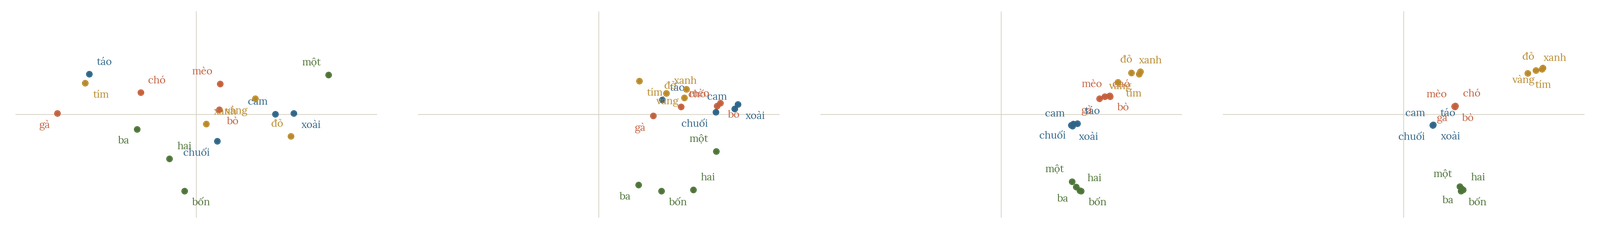

**Hỏi nhanh.** Với `padding_idx=0` và loss là `embedding(ids).sum()`, batch là `ids = [[4, 4, 0], [4, 2, 0]]`. Gradient của hàng 4 và của hàng 0 là gì?

- A. Hàng 4 nhận `[3, 3]`, hàng 0 nhận `[0, 0]`
- B. Hàng 4 nhận `[1, 1]`, hàng 0 nhận `[0, 0]`
- C. Hàng 4 nhận `[2, 2]`, hàng 0 nhận `[0, 0]`
- D. Hàng 4 nhận `[3, 3]`, hàng 0 nhận `[2, 2]`

<details><summary>Đáp án</summary>

A. Hàng 4 nhận `[3, 3]`, hàng 0 nhận `[0, 0]`

Token 4 xuất hiện ba lần, mỗi lần góp $[1, 1]$. `[1, 1]` là nhầm rằng mỗi loại token chỉ được tra một lần. `[2, 2]` là chỉ đếm câu đầu. PAD xuất hiện hai lần, nhưng `padding_idx` chặn gradient, nên hàng 0 nhận 0.

</details>

## Mean pooling mất thứ tự

Mean của “đồ_thị dp” và “dp đồ_thị” bằng nhau. Ta đổi vị trí và kiểm:

In [ ]:
pair = torch.tensor([[2, 3], [3, 2]])
pair_vectors = masked_mean(embedding(pair), pair.ne(PAD))
print('same after swapping:', torch.allclose(pair_vectors[0], pair_vectors[1]))

same after swapping: True


Phép cộng giao hoán nên mean pooling mất thứ tự. Nó là baseline tốt khi nhãn phụ thuộc chủ yếu vào tập từ (chủ đề, từ khóa), nhưng không đủ khi “A thắng B” khác “B thắng A”.

Muốn phân biệt, token phải tương tác với vị trí **trước khi pooling**: RNN ở mục sau đọc lần lượt từng token; self-attention kèm thông tin vị trí ở bài 3.9 cho mọi token nhìn nhau. Chỉ cộng vector vị trí (positional encoding) rồi lấy mean ngay vẫn chưa đủ: tổng vector token và tổng vector vị trí đều không đổi khi hoán vị token trong cùng các slot. Self-attention không có tín hiệu vị trí rồi mean cuối cũng giữ tính bất biến hoán vị. Embedding riêng chỉ gán vector cho token, chưa cho token biết ngữ cảnh câu.

**Hỏi nhanh.** Cộng một vector vị trí $\mathbf p_t$ vào embedding của token ở vị trí $t$, rồi lấy mean ngay. Hai câu “A thắng B” và “B thắng A” cho ra biểu diễn thế nào?

- A. Khác nhau, vì giờ mỗi token mang theo vị trí của nó
- B. Giống nhau, vì tổng các token và tổng các vị trí đều không đổi
- C. Khác nhau, vì A và B mang hai ID khác nhau
- D. Giống nhau, nhưng chỉ khi vector của A và B trùng nhau

<details><summary>Đáp án</summary>

B. Giống nhau, vì tổng các token và tổng các vị trí đều không đổi

Mean bằng $\big(\sum\mathbf e_{\text{token}} + \sum_t\mathbf p_t\big)/3$. Tổng thứ nhất không phụ thuộc token nào ngồi ở vị trí nào. Tổng thứ hai chỉ phụ thuộc độ dài câu. Vị trí chỉ có tác dụng khi token và vị trí được trộn với nhau trước một phép gộp đối xứng, chẳng hạn qua RNN hay attention. ID khác nhau cũng không cứu được, vì phép cộng vẫn có tính giao hoán.

</details>

## RNN đọc theo thứ tự, nhưng phải dừng đúng chỗ

Recurrent neural network (RNN) đọc chuỗi như một vòng lặp có trạng thái, giống duyệt mảng và cập nhật một biến tích lũy trong CP. Với vector token $\mathbf x_t$ và trạng thái ẩn (hidden state) $\mathbf h_{t-1}$:

$$\mathbf h_t=\tanh\big(W_{xh}\mathbf x_t+W_{hh}\mathbf h_{t-1}+\mathbf b\big),\qquad \mathbf h_0=\mathbf 0.$$

$W_{xh}$ có shape `(H,d)`, $W_{hh}$ shape `(H,H)`, dùng chung cho mọi bước nên một RNN nhận chuỗi dài bao nhiêu cũng được. Trạng thái sau token cuối là một bản tóm tắt có thứ tự: đổi chỗ hai token là đổi thứ tự cập nhật, kết quả khác. Vì vậy RNN và LSTM không cần mã hóa vị trí như Transformer ở bài 3.9.

`nn.RNN` của PyTorch lưu hai bias `bias_ih`, `bias_hh` (tổng của chúng đóng vai $\mathbf b$), nên với $d=2$, $H=3$ có $3\cdot2+3\cdot3+3+3=21$ tham số.

Với batch đã pad, RNN vẫn chạy qua mọi cột. Ô PAD có vector 0 nhưng bước cập nhật vẫn là $\tanh(W_{hh}\mathbf h_{t-1}+\mathbf b)$, nên trạng thái tiếp tục đổi. Đọc cột cuối `outputs[:, -1]` là đọc trạng thái **sau** các PAD. Code dưới so cột cuối với trạng thái tại token thật cuối cùng (chỉ số `lengths-1`), và với `pack_padded_sequence`, cách PyTorch cho RNN bỏ hẳn các bước PAD.

In [ ]:
from torch.nn.utils.rnn import pack_padded_sequence

torch.manual_seed(38)
rnn = nn.RNN(input_size=2, hidden_size=3, batch_first=True)
print('RNN parameters:', sum(p.numel() for p in rnn.parameters()))
with torch.no_grad():
    outputs, _ = rnn(vectors)                       # (B, L, H): trạng thái sau từng cột
    lengths = valid_mask.sum(dim=1)
    last_column = outputs[:, -1]                    # cột cuối, có thể nằm sau PAD
    last_valid = outputs[torch.arange(len(ids)), lengths - 1]
    packed = pack_padded_sequence(vectors, lengths, batch_first=True, enforce_sorted=False)
    _, h_packed = rnn(packed)                       # (1, B, H): dừng ở token thật cuối
    swapped = rnn(embedding(pair))[0][:, -1]
print('outputs shape:', tuple(outputs.shape))
print('last column is last token:', torch.isclose(last_column, last_valid).all(dim=1).tolist())
print('gather matches packed:', torch.allclose(last_valid, h_packed[0]))
print('RNN same after swapping:', torch.allclose(swapped[0], swapped[1]))

RNN parameters: 21
outputs shape: (3, 3, 3)
last column is last token: [False, False, True]
gather matches packed: True
RNN same after swapping: False


Dòng `[False, False, True]` cho thấy chỉ câu thứ ba, câu không có PAD, có cột cuối đúng là token thật cuối. Hai câu kia nếu đọc cột cuối sẽ nhận trạng thái đã đi qua một hoặc hai PAD; model vẫn train được, nhưng biểu diễn phụ thuộc lượng PAD, đúng lỗi mà masked mean đã tránh. Lấy theo `lengths-1` khớp với bản packed. Dòng cuối xác nhận RNN phân biệt “đồ_thị dp” với “dp đồ_thị”, điều mean pooling không làm được.



**Hỏi nhanh.** Phân loại câu bằng RNN với `batch_first=True`, batch được pad bên phải. Đội A lấy `outputs[:, -1]`, đội B lấy `outputs[i, lengths[i]-1]`. Validation của đội A thấp hơn, và còn đổi khi xáo lại các batch. Vì sao?

- A. A đọc trạng thái đã chạy qua PAD, mà lượng PAD đổi theo batch
- B. A đọc trạng thái ở đầu chuỗi, khi chưa thấy các token sau
- C. B đọc nhầm PAD, vì `lengths` đếm cả token đặc biệt
- D. Hai cách như nhau, vì vector PAD bằng 0 ở mọi bước

<details><summary>Đáp án</summary>

A. A đọc trạng thái đã chạy qua PAD, mà lượng PAD đổi theo batch

Pad bên phải thì cột cuối của câu ngắn nằm sau các PAD, và mỗi bước PAD vẫn cập nhật trạng thái qua $W_{hh}$ và bias. Lượng PAD phụ thuộc vào câu dài nhất trong batch, nên xáo batch là đổi biểu diễn. Chỉ số `-1` là cột cuối, không phải đầu chuỗi. `lengths` lấy từ mask nên đếm đúng số token thật. Vector PAD bằng 0 cũng không làm bước cập nhật đứng yên.

</details>

## Chuỗi dài: gradient tắt dần và LSTM

RNN nhìn được cả chuỗi về lý thuyết, nhưng có học được quan hệ xa hay không là chuyện gradient. Trải theo $L$ bước, RNN là một mạng sâu $L$ lớp dùng chung $W_{hh}$, nên gặp đúng hiện tượng gradient tắt dần của bài 3.3, chỉ là theo chiều thời gian.

Đạo hàm của trạng thái cuối $\mathbf h_L$ theo token thứ $t$ đi qua $L-t$ bước, mỗi bước nhân một ma trận Jacobian gồm $W_{hh}$ và đạo hàm tanh (không quá 1). Với số vô hướng $h_t=w\,h_{t-1}+x_t$, ta có $\partial h_L/\partial x_t=w^{L-t}$: $|w|<1$ thì tắt theo cấp số nhân (vanishing gradient), $|w|>1$ thì bùng nổ (exploding gradient). Đo trên RNN của mục trước với một chuỗi ngẫu nhiên dài 40:

In [ ]:
torch.manual_seed(0)
long_x = torch.randn(1, 40, 2, requires_grad=True)
_, h_end = rnn(long_x)
h_end.sum().backward()
grad_norm = long_x.grad[0].norm(dim=1)              # độ lớn gradient theo từng token
for t in [40, 30, 20, 10, 1]:
    print(f'token {t:2d}: {grad_norm[t - 1].item():.1e}')

token 40: 4.5e-01
token 30: 1.3e-03
token 20: 8.4e-06
token 10: 1.9e-08
token  1: 1.9e-10


Token cuối nhận gradient cỡ $0.45$, token thứ 30 còn $1.3\cdot10^{-3}$, token đầu chỉ $1.9\cdot10^{-10}$: cứ mười bước, gradient giảm hai đến ba bậc. Nếu nhãn phụ thuộc vài token ở đầu một chuỗi dài, tín hiệu sửa trọng số theo các token ấy gần như bằng 0. Đây là lý do chính khiến RNN “quên” đầu chuỗi: trạng thái có thể đủ chỗ chứa điều cần nhớ, nhưng gradient quá nhỏ để dạy model giữ lại nó. Tăng hidden size không bỏ được phép nhân lặp.

Chiều ngược lại, gradient bùng nổ, được chặn bằng gradient clipping (bài 3.7 dùng nó cùng GradScaler). Clip theo chuẩn giữ hướng: gradient $(3, 4)$ có chuẩn 5, `max_norm=1` cho $(0.6, 0.8)$; clip theo giá trị về $[-1, 1]$ cho $(1, 1)$, đổi cả hướng.



LSTM (long short-term memory) sửa ngay trên đường đi của gradient. Ngoài $\mathbf h_t$, LSTM giữ một cell state cập nhật bằng phép cộng có cổng:

$$\mathbf c_t=\mathbf f_t\odot\mathbf c_{t-1}+\mathbf i_t\odot\tilde{\mathbf c}_t,$$

với forget gate $\mathbf f_t$ và input gate $\mathbf i_t$ nằm trong $(0,1)$, do mạng tự học từ $\mathbf x_t$ và $\mathbf h_{t-1}$; $\tilde{\mathbf c}_t$ là nội dung mới đề xuất. Đường trực tiếp từ $\mathbf c_{t-1}$ tới $\mathbf c_t$ chỉ nhân với $\mathbf f_t$: khi cổng quên gần 1, gradient đi qua nhiều bước mà không bị nhân nhỏ dần, cùng ý với kết nối residual ở bài 3.9. GRU là biến thể gọn hơn cùng ý tưởng.

LSTM có bốn khối (ba cổng và nội dung mới), mỗi khối $H(d + H)$ trọng số và hai bias $H$: `nn.LSTM(64, 128)` có $4 \cdot 128 \cdot 192 + 8 \cdot 128 = 99\,328$ tham số. Trong PyTorch, `nn.LSTM` gọi giống hệt `nn.RNN`, kể cả với `pack_padded_sequence`; chỉ khác là trạng thái cuối trả về dạng cặp `(h_n, c_n)`.

Cổng giúp nhớ xa hơn nhưng vẫn đi tuần tự từng bước; attention ở bài 3.9 nối thẳng mọi cặp vị trí.



**Hỏi nhanh.** RNN một chiều số $h_t = w\,h_{t-1} + x_t$, chuỗi dài 30. Đạo hàm $\partial h_{30}/\partial x_1$ bằng bao nhiêu khi $w = 0.5$, và khi $w = 1.5$?

- A. $0.5\cdot 29 = 14.5$ và $1.5\cdot 29 = 43.5$
- B. Bằng 1 với mọi $w$, vì $x_1$ cộng thẳng vào trạng thái
- C. Khoảng $9.3\cdot 10^{-10}$ và $1.9\cdot 10^{5}$
- D. Khoảng $1.9\cdot 10^{-9}$ và $1.3\cdot 10^{5}$

<details><summary>Đáp án</summary>

D. Khoảng $1.9\cdot 10^{-9}$ và $1.3\cdot 10^{5}$

$x_1$ đi vào $h_1$ với hệ số 1, rồi qua 29 bước, mỗi bước nhân với $w$, nên đạo hàm là $w^{29}$. $0.5^{29} \approx 1.9\cdot 10^{-9}$, tức gradient tắt. $1.5^{29} \approx 1.3\cdot 10^{5}$, tức gradient bùng nổ. Nhân $w\cdot 29$ là nhầm phép nhân lặp thành phép cộng lặp. $w^{30}$ là đếm thừa một bước. Hệ số 1 chỉ đúng ở bước đầu tiên.

</details>

## Khi đi thi

- Lưu vocabulary, PAD, UNK và độ dài tối đa cùng checkpoint; lúc suy luận phải dùng đúng các quy ước ấy.
- Chạy baseline masked mean cộng linear trước khi thử RNN hay Transformer.
- Thêm vài cột PAD vào một batch: biểu diễn phải giữ nguyên.

## Tóm tắt

- Embedding tra mỗi ID ra một vector học được: `(B, L)` thành `(B, L, d)`.
- Padding tạo bảng chữ nhật; mask đánh dấu token thật để pooling và attention bỏ qua PAD.
- Masked mean chia cho số token thật; thêm PAD không được làm đổi kết quả. Chuỗi rỗng cần một quy tắc rõ.
- Mean pooling bỏ thứ tự. RNN giữ thứ tự, nhưng phải đọc trạng thái tại token thật cuối; trên chuỗi dài gradient tắt dần, LSTM giảm bớt bằng cell state có cổng.

## Kiểm tra cuối bài

**Câu 1.** Vocabulary có 20 000 từ. Nếu mỗi từ được biểu diễn bằng one-hot, cosine similarity giữa “giỏi” và “xuất_sắc” bằng bao nhiêu, và một embedding dense đã học thì khác ở chỗ nào?

- A. Cosine bằng 0 như mọi cặp từ, còn embedding dense đã học có thể đặt hai từ gần nhau
- B. Cosine bằng 1 vì hai từ cùng nghĩa, còn embedding dense chỉ giúp tiết kiệm bộ nhớ
- C. Cosine bằng 0.5 vì hai vector cùng độ dài, còn embedding dense luôn cho cosine bằng 1
- D. Cosine tùy ID của hai từ, còn embedding dense bỏ được nhu cầu phải có vocabulary

<details><summary>Đáp án</summary>

A. Cosine bằng 0 như mọi cặp từ, còn embedding dense đã học có thể đặt hai từ gần nhau

Hai vector one-hot khác nhau thì vuông góc, nên tích vô hướng bằng 0. Mọi cặp từ đều cách đều nhau, one-hot không chứa quan hệ nghĩa nào, và không phụ thuộc ID. Vector dense có vài chục đến vài trăm thành phần do mục tiêu học quyết định, nên hai từ được dùng giống nhau có thể nằm gần nhau. Dense vẫn cần vocabulary để biết tra hàng nào.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 217](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=79)

</details>

**Câu 2.** Train word2vec (skip-gram) từ một bảng ngẫu nhiên, trên nhiều bài tường thuật bóng đá. Train xong, cosine giữa “thắng” và “thua” rất cao. Giải thích nào đúng?

- A. Train bị lỗi, vì skip-gram phải đẩy hai từ trái nghĩa ra xa nhau
- B. Hai từ có ID kề nhau, nên khởi tạo đã đặt chúng gần nhau
- C. Mục tiêu là đoán các từ xung quanh, mà hai từ này có ngữ cảnh rất giống nhau
- D. Skip-gram học theo nhãn chủ đề, và cả hai từ cùng nhãn thể thao

<details><summary>Đáp án</summary>

C. Mục tiêu là đoán các từ xung quanh, mà hai từ này có ngữ cảnh rất giống nhau

“Đội A thắng trận”, “đội A thua trận”: hai từ ở giữa đi cùng gần như đúng những từ ngữ cảnh ấy. Vì vậy gradient của mục tiêu đoán ngữ cảnh đẩy hai hàng theo cùng một hướng. Embedding kiểu này đo “được dùng giống nhau”, không đo “cùng nghĩa”. Bài phân loại cảm xúc cần fine-tune embedding cùng với classifier, hoặc kiểm trên validation trước khi tin vào nó. Skip-gram không có cơ chế đẩy từ trái nghĩa ra xa, không dùng nhãn, và ID không mang thông tin gì.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 218](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=79)

</details>

**Câu 3.** Trong các bài toán sau, bài nào **ít** cần một mô hình chuỗi như RNN nhất?

- A. Nhận dạng lời nói từ một đoạn ghi âm
- B. Gợi ý sửa chính tả trong lúc đang gõ phím
- C. Sáng tác tiếp một đoạn nhạc theo từng nốt
- D. Nhận diện khuôn mặt từ một ảnh chụp

<details><summary>Đáp án</summary>

D. Nhận diện khuôn mặt từ một ảnh chụp

Lời nói, chuỗi phím gõ và bản nhạc đều là dãy theo thời gian: phần tử sau phụ thuộc phần trước, và độ dài thay đổi. Đó đúng là loại dữ liệu RNN xử lý. Ảnh khuôn mặt là một lưới pixel có kích thước cố định với cấu trúc không gian, và CNN ở chương sau hợp với nó hơn.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q1.5](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=8)

</details>

**Câu 4.** UNK là token thật nhưng chưa có trong vocabulary, còn PAD chỉ để ghép batch. Khi masked mean bỏ qua PAD, thì UNK nên được xử lý thế nào?

- A. Bỏ cả UNK, vì cả hai đều không mang nội dung chữ cụ thể
- B. Giữ UNK như một token thật, có hàng embedding riêng
- C. Đổi UNK thành PAD, nhưng vẫn lấy số token gốc làm mẫu số
- D. Bỏ UNK khỏi tử số, nhưng vẫn đếm nó ở mẫu số

<details><summary>Đáp án</summary>

B. Giữ UNK như một token thật, có hàng embedding riêng

UNK chiếm một vị trí có nội dung, kiểu “ở đây có một từ lạ”. Hàng embedding của nó được học, và tỉ lệ từ lạ cũng là thông tin. Bỏ UNK hay đổi nó thành PAD là xóa thông tin ấy. Tử số và mẫu số dùng hai quy tắc khác nhau thì mean bị sai thang.

</details>

**Câu 5.** Ba biến thể RNN, bỏ bias, với trạng thái $\mathbf s_t\in\mathbb R^m$ và đầu vào $\mathbf x_t\in\mathbb R^d$. (1) $\mathbf s_t = f(W_{ss}\mathbf s_{t-1} + W_{sx}\mathbf x_t)$. (2) $\mathbf s_t = f\big(W_{ssx}[\mathbf s_{t-1};\mathbf x_t]\big)$, với $W_{ssx}$ có shape $m\times(m+d)$. (3) $\mathbf s_t = f(W_{ss}\mathbf s_{t-1}) + f(W_{sx}\mathbf x_t)$. Với $f = \tanh$, câu nào đúng?

- A. Cả ba luôn tương đương, với mọi hàm $f$
- B. (1) và (2) tương đương, với $W_{ssx} = [W_{ss}\;W_{sx}]$
- C. (1) và (3) tương đương, vì tanh là hàm lẻ
- D. Không cặp nào tương đương, khi $f$ là hàm phi tuyến

<details><summary>Đáp án</summary>

B. (1) và (2) tương đương, với $W_{ssx} = [W_{ss}\;W_{sx}]$

Ghép hai ma trận theo cột rồi nhân với vector ghép thì $[W_{ss}\;W_{sx}]\,[\mathbf s;\mathbf x] = W_{ss}\mathbf s + W_{sx}\mathbf x$. Vì vậy (2) chỉ là một cách viết khác của (1), với mọi $f$. (3) cộng **sau** khi qua $f$, mà nói chung $\tanh a + \tanh b \ne \tanh(a + b)$, chẳng hạn với $a = b = 1$ thì ra $1.52$ so với $0.96$. Tính lẻ không giúp gì ở đây. Chỉ khi $f$ tuyến tính, như $f(z) = z$, thì cả ba mới trùng nhau.
Phỏng theo: [MIT 6.036 · Final, Spring 2022 · Q9(a)](https://introml.mit.edu/_static/fall22/final/review/6036_final_sp22.pdf#page=23)

</details>

**Câu 6.** Một RNN thường phân loại các review dài khoảng 400 token. Nhãn thường do câu đầu quyết định, kiểu “Không nên mua: …”, nhưng model chỉ học được tín hiệu từ vài chục token cuối. Nguyên nhân chính là gì, và sửa theo hướng nào?

- A. Gradient về tới token đầu bị tắt dần qua nhiều bước, nên dùng LSTM, GRU hoặc attention
- B. Trạng thái ẩn quá nhỏ để chứa 400 token, nên tăng hidden size lên gấp bốn
- C. Dữ liệu lệch về các token gần cuối, nên cân bằng lại số mẫu của từng nhãn
- D. Learning rate quá nhỏ cho token đầu, nên tăng riêng learning rate của embedding

<details><summary>Đáp án</summary>

A. Gradient về tới token đầu bị tắt dần qua nhiều bước, nên dùng LSTM, GRU hoặc attention

Tín hiệu từ token đầu phải đi qua khoảng 400 phép nhân Jacobian. Phép đo trong bài cho thấy chỉ 40 bước đã kéo gradient từ $0.45$ xuống $1.9\cdot 10^{-10}$. LSTM và GRU tạo một đường cộng có cổng, còn attention nối thẳng các vị trí với nhau. Để ra nhãn, chỉ cần giữ một ý ngắn của câu đầu, chứ không cần chứa cả 400 token. Trạng thái kích thước cố định là giới hạn thật khi phải nhớ nhiều chi tiết, nhưng ở đây tăng hidden size không bỏ được phép nhân lặp. Cân bằng nhãn không liên quan tới vị trí. Gradient gần 0 nhân với learning rate lớn thì vẫn gần 0, còn các token cuối lại mất ổn định.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q2.3](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=11)

</details>

**Câu 7.** Model chỉ nhận tối đa 512 token. Bài luận trong dữ liệu dài trung bình 1000 token, và điểm phụ thuộc nhiều vào phần kết luận ở cuối. Cách cắt mặc định giữ 512 token đầu. Nên làm thế nào?

- A. Giữ 512 token đầu, vì mở bài luôn chứa ý chính
- B. Bỏ giới hạn, pad mọi bài lên 1000 token cho khỏi mất thông tin
- C. Chia bài thành các đoạn không quá 512 token, dự đoán từng đoạn rồi gộp lại
- D. Giảm `max_len` xuống 256 cho batch lớn hơn và train nhanh hơn

<details><summary>Đáp án</summary>

C. Chia bài thành các đoạn không quá 512 token, dự đoán từng đoạn rồi gộp lại

Cắt giữ phần đầu là bỏ đúng phần quyết định điểm. Chia đoạn rồi gộp, hoặc giữ cả đầu lẫn cuối, thì giữ được phần kết luận; chọn giữa các cách bằng validation. Model không nhận quá 512 token, nên không thể pad lên 1000. Giảm xuống 256 thì bỏ thêm dữ liệu thật.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q2.2](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=10)

</details>

**Câu 8.** Optimizer chứa cả embedding lẫn classifier, nhưng code gọi `classifier(pooled.detach())` trước khi tính loss. Muốn embedding học được từ loss phân loại, phải sửa gì?

- A. Bỏ `detach`, để gradient đi qua bước gộp về tới embedding
- B. Giữ `detach`, tăng learning rate riêng cho embedding
- C. Giữ `detach`, gọi thêm `model.train()` trước khi tính loss
- D. Chỉ `zero_grad` cho classifier, giữ lại gradient của embedding

<details><summary>Đáp án</summary>

A. Bỏ `detach`, để gradient đi qua bước gộp về tới embedding

`detach` cắt đồ thị tính toán. Optimizer có chứa embedding, nhưng các hàng embedding không nhận được gradient nào từ loss này, nên tăng learning rate cũng chẳng có gì để nhân. `model.train()` chỉ đổi chế độ của dropout và BatchNorm. `zero_grad` không tạo ra đường đi mới cho gradient.

</details>

**Câu 9.** `nn.Embedding(10000, 64)` nối với `nn.RNN(64, 128)`, một lớp, có bias như mặc định. Tổng số tham số là bao nhiêu?

- A. 24 832
- B. 656 640
- C. 664 704
- D. 664 832

<details><summary>Đáp án</summary>

D. 664 832

Embedding có $10\,000\cdot 64 = 640\,000$ tham số. RNN có `weight_ih` là $128\cdot 64 = 8192$, `weight_hh` là $128\cdot 128 = 16\,384$, và hai bias là $2\cdot 128 = 256$, cộng lại $24\,832$. Tổng là $664\,832$, trong đó bảng embedding chiếm khoảng 96%. Ra 24 832 là quên embedding. Ra 656 640 là quên `weight_ih`. Ra 664 704 là chỉ tính một bias.

</details>

**Câu 10.** Để `outputs[:, -1]` luôn rơi vào token thật, một đội đổi sang pad bên **trái**: câu “dp” thành `[0, 0, 3]`. RNN có bias khác 0, và $\mathbf h_0 = \mathbf 0$. Kiểm tính không đổi khi thêm PAD thì cho kết quả gì?

- A. Đạt, vì PAD có vector 0 nên các bước đầu giữ $\mathbf h = \mathbf 0$
- B. Không đạt, vì hai bước PAD đã làm đổi $\mathbf h$ trước khi gặp “dp”
- C. Đạt, vì cột cuối là token thật nên mọi PAD đều bị bỏ qua
- D. Không đạt, vì pad bên trái làm đảo thứ tự các token thật

<details><summary>Đáp án</summary>

B. Không đạt, vì hai bước PAD đã làm đổi $\mathbf h$ trước khi gặp “dp”

Bước PAD đầu tiên tính $\mathbf h_1 = \tanh(W_{hh}\mathbf 0 + \mathbf b) = \tanh(\mathbf b) \ne \mathbf 0$. Vì vậy “dp” được đọc từ một trạng thái khác $\mathbf h_0$, và kết quả đổi theo số PAD. Pad trái sửa được chỗ đọc, nhưng không sửa được việc RNN chạy qua PAD; packed sequence mới bỏ hẳn được các bước ấy. Thứ tự các token thật thì không đổi.

</details>

## Đọc thêm

- [PyTorch 2.9 — Embedding](https://docs.pytorch.org/docs/2.9/generated/torch.nn.Embedding.html): tra `padding_idx`, shape và cách cập nhật hàng embedding.
- [PyTorch 2.9 — pad_sequence](https://docs.pytorch.org/docs/2.9/generated/torch.nn.utils.rnn.pad_sequence.html): đọc `batch_first` và padding để tự ghép chuỗi.
- [D2L — Word Embedding](https://d2l.ai/chapter_natural-language-processing-pretraining/word2vec.html): xem vì sao mục tiêu học tạo quan hệ giữa các vector token.
- [PyTorch 2.9 — pack_padded_sequence](https://docs.pytorch.org/docs/2.9/generated/torch.nn.utils.rnn.pack_padded_sequence.html): đọc `lengths`, `enforce_sorted` và cách RNN bỏ các bước PAD.
- [D2L — Long Short-Term Memory](https://d2l.ai/chapter_recurrent-modern/lstm.html): các cổng của LSTM, viết từ đầu rồi đối chiếu với `nn.LSTM`.